# Heating & cooling load prediction for buildings

Dataset: UCI *Energy Efficiency* (Tsanas & Xifara, 2012) – 768 simulated buildings with 8 design
parameters and two targets, heating load (Y1) and cooling load (Y2), both in kWh/m².

Question: how well can simple regression models estimate the loads from the design alone,
and which design parameters matter most?

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.base import clone
from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [2]:
df = pd.read_csv("ENB2012_data.csv")
df = df.rename(columns={
    "X1": "compactness", "X2": "surface_area", "X3": "wall_area", "X4": "roof_area",
    "X5": "height", "X6": "orientation", "X7": "glazing_area", "X8": "glazing_dist",
    "Y1": "heating_load", "Y2": "cooling_load",
})
print(df.shape)
df.describe().T.round(2)

(768, 10)


,count,mean,std,min,25%,50%,75%,max
compactness,768.0,0.76,0.11,0.62,0.68,0.75,0.83,0.98
surface_area,768.0,671.71,88.09,514.50,606.38,673.75,741.12,808.50
wall_area,768.0,318.50,43.63,245.00,294.00,318.50,343.00,416.50
roof_area,768.0,176.60,45.17,110.25,140.88,183.75,220.50,220.50
height,768.0,5.25,1.75,3.50,3.50,5.25,7.00,7.00
orientation,768.0,3.50,1.12,2.00,2.75,3.50,4.25,5.00
glazing_area,768.0,0.23,0.13,0.00,0.10,0.25,0.40,0.40
glazing_dist,768.0,2.81,1.55,0.00,1.75,3.00,4.00,5.00
heating_load,768.0,22.31,10.09,6.01,12.99,18.95,31.67,43.10
cooling_load,768.0,24.59,9.51,10.90,15.62,22.08,33.13,48.03


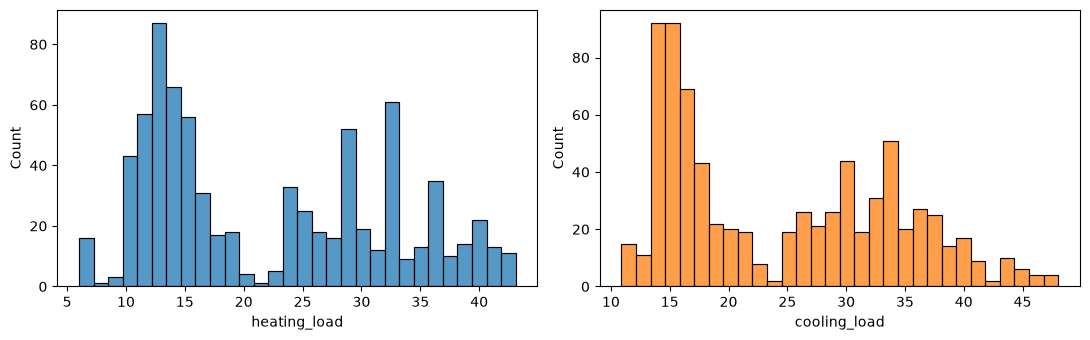

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
sns.histplot(df["heating_load"], ax=ax[0], bins=30)
sns.histplot(df["cooling_load"], ax=ax[1], bins=30, color="tab:orange")
plt.tight_layout(); plt.show()

# the two-hump shape comes from building height (3.5 m vs 7 m)

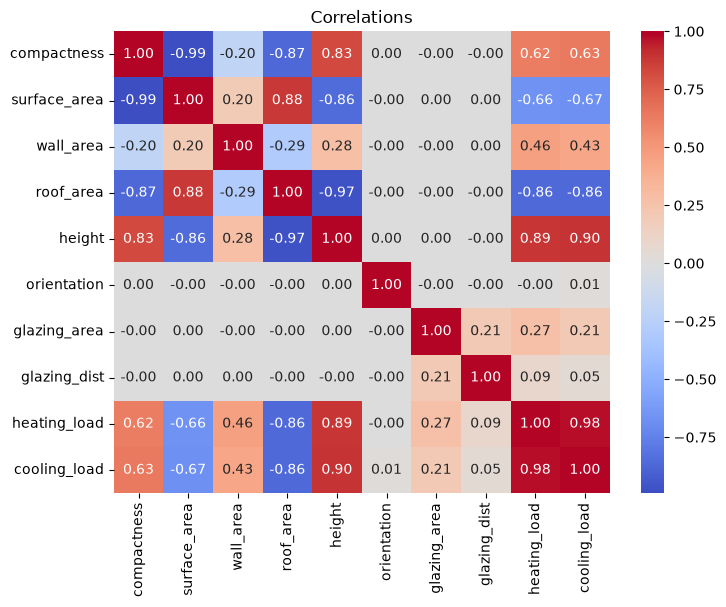

In [4]:
plt.figure(figsize=(8, 6))
sns.heatmap(df.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlations")
plt.show()

## Models

Same split for both targets. Besides the hold-out test set I also run 5-fold CV on the training
part, since with 768 rows a single split can be a bit lucky.

In [5]:
features = ["compactness", "surface_area", "wall_area", "roof_area",
            "height", "orientation", "glazing_area", "glazing_dist"]
targets = ["heating_load", "cooling_load"]

X = df[features]
X_train, X_test, Y_train, Y_test = train_test_split(X, df[targets], test_size=0.2, random_state=42)

models = {
    "Linear regression": LinearRegression(),
    "Decision tree": DecisionTreeRegressor(random_state=42),
    "Random forest": RandomForestRegressor(n_estimators=300, random_state=42),
    "Gradient boosting": GradientBoostingRegressor(random_state=42),
}

In [6]:
kf = KFold(5, shuffle=True, random_state=42)
rows, fitted = [], {}

for tgt in targets:
    for name, base in models.items():
        mdl = clone(base)  # fresh copy per target
        cv_r2 = cross_val_score(mdl, X_train, Y_train[tgt], cv=kf, scoring="r2").mean()
        mdl.fit(X_train, Y_train[tgt])
        pred = mdl.predict(X_test)
        fitted[(tgt, name)] = (mdl, pred)
        rows.append({
            "target": tgt, "model": name,
            "CV R²": cv_r2,
            "test R²": r2_score(Y_test[tgt], pred),
            "test MAE": mean_absolute_error(Y_test[tgt], pred),
            "test RMSE": np.sqrt(mean_squared_error(Y_test[tgt], pred)),
        })

results = pd.DataFrame(rows).round(3)
results

,target,model,CV R²,test R²,test MAE,test RMSE
0,heating_load,Linear regression,0.915,0.912,2.182,3.025
1,heating_load,Decision tree,0.996,0.996,0.425,0.621
2,heating_load,Random forest,0.997,0.998,0.351,0.489
3,heating_load,Gradient boosting,0.998,0.997,0.386,0.515
4,cooling_load,Linear regression,0.883,0.893,2.195,3.145
5,cooling_load,Decision tree,0.944,0.956,1.156,2.017
6,cooling_load,Random forest,0.967,0.967,1.079,1.749
7,cooling_load,Gradient boosting,0.974,0.975,1.055,1.513


Tree ensembles are clearly better than linear regression – the relationships aren't linear
(e.g. height is basically a switch). Cooling load is harder to predict than heating.

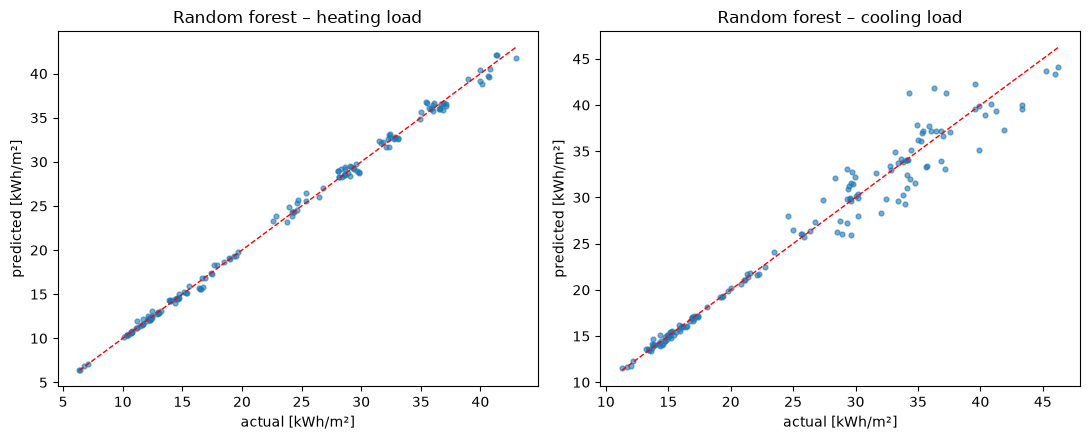

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
for a, tgt in zip(ax, targets):
    _, pred = fitted[(tgt, "Random forest")]
    a.scatter(Y_test[tgt], pred, s=12, alpha=0.6)
    lims = [Y_test[tgt].min(), Y_test[tgt].max()]
    a.plot(lims, lims, "r--", lw=1)
    a.set_xlabel("actual [kWh/m²]"); a.set_ylabel("predicted [kWh/m²]")
    a.set_title(f"Random forest – {tgt.replace('_', ' ')}")
plt.tight_layout(); plt.show()

## What drives the load?

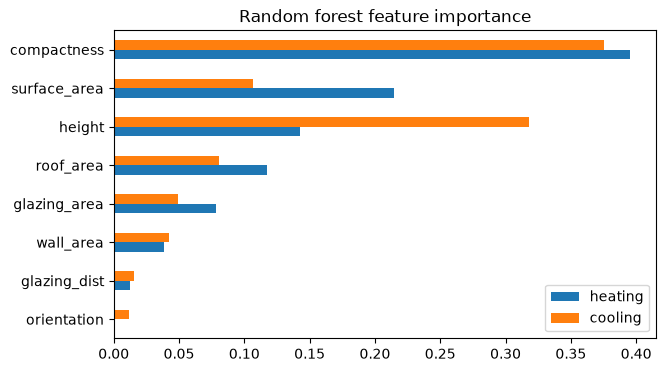

In [8]:
rf_heat = fitted[("heating_load", "Random forest")][0]
rf_cool = fitted[("cooling_load", "Random forest")][0]
imp = pd.DataFrame({"heating": rf_heat.feature_importances_,
                    "cooling": rf_cool.feature_importances_}, index=features)
imp.sort_values("heating").plot.barh(figsize=(7, 4))
plt.title("Random forest feature importance")
plt.show()

Roof area, height and compactness dominate (they're all strongly correlated – taller, more
compact buildings have less envelope per m² floor). Glazing area is the main thing a designer
could change after the building shape is fixed. Orientation barely matters in this dataset.